# PM2.5 Regression + Kriging (Standard Layers)

This notebook mirrors the temperature workflow and models **PM2.5** using the standard layers in `README.md`: NDVI, impervious surface, road density, emissions (NEI), and population density.

In [11]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        has_data = (candidate / "data" / "spatial" / "grid_rectangles.geojson").exists()
        has_src = (candidate / "src").exists()
        if has_data and has_src:
            return candidate
    raise FileNotFoundError("Could not find project root from current notebook path.")


PROJECT_ROOT = find_project_root(Path.cwd())
DATA_DIR = PROJECT_ROOT / "data"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.time_series.series_aligner import align_sensor_series
from src.kriging.ridge_regression import train_ridge, ridge_predict
from src.kriging.variogram_training import fit_variogram_model, plot_variogram_fit, ordinary_kriging_predict

print(f"PROJECT_ROOT: {PROJECT_ROOT}")

PROJECT_ROOT: /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis


In [12]:
# Load extracted PM2.5 layers
LAYER_DIR = DATA_DIR / "kriging_satellite" / "layers"

required_layer_paths = {
    "ndvi": LAYER_DIR / "ndvi_grid.geojson",
    "ndbi": LAYER_DIR / "ndbi_grid.geojson",
    "impervious": LAYER_DIR / "nlcd_impervious_grid.geojson",
    "road_density": LAYER_DIR / "road_density_grid.geojson",
    # "emissions": LAYER_DIR / "nei_emissions_grid.geojson",
    # "population_density": LAYER_DIR / "population_density_grid.geojson",
}

missing_required = [name for name, path in required_layer_paths.items() if not path.exists()]
if missing_required:
    raise FileNotFoundError(f"Missing required PM2.5 layers: {missing_required}")

layer_gdfs = {name: gpd.read_file(path) for name, path in required_layer_paths.items()}
print("Loaded required layers:", list(required_layer_paths.keys()))

Loaded required layers: ['ndvi', 'ndbi', 'impervious', 'road_density']


In [13]:
# Load Boston sensor series and compute mean PM2.5 between 15:00 and 16:00
SENSORS_DIR = DATA_DIR / "sensors"
sensor_csvs = {
    "Boston Carter Field": SENSORS_DIR / "boston_carter_field" / "boston_carter_field.csv",
    "Boston Gainsborough Parking Garage": SENSORS_DIR / "boston_gainsborough_parking" / "boston_gainsborough_parking.csv",
    "Boston Robinson Hall": SENSORS_DIR / "boston_robinson_hall" / "boston_robinson_hall.csv",
    "Boston West Village B": SENSORS_DIR / "boston_west_village_b" / "boston_west_village_b.csv",
    "Boston World Series Way": SENSORS_DIR / "boston_world_series_way" / "boston_world_series_way.csv",
}

missing_csvs = [name for name, path in sensor_csvs.items() if not path.exists()]
if missing_csvs:
    raise FileNotFoundError(f"Missing sensor CSV files for: {missing_csvs}")

all_sensors = {name: pd.read_csv(path) for name, path in sensor_csvs.items()}

aligned_df, lag_info = align_sensor_series(
    sensor_dataframes=all_sensors,
    variable_name="pm25",
    time_column="timestamp",
    sampling_interval="1min",
    timestamp_tolerance="15min",
)

initial_time = "15:00"
final_time = "16:00"
aligned_between = aligned_df.between_time(initial_time, final_time)
if aligned_between.empty:
    raise ValueError("No aligned PM2.5 data between 15:00 and 16:00.")

measurements_at_timestamp = aligned_between.mean(axis=0)

sensor_locations = pd.read_json(DATA_DIR / "spatial" / "sensor_locations.json")
sensor_names = list(sensor_csvs.keys())

sensor_pm25 = measurements_at_timestamp.reindex(sensor_names)
if sensor_pm25.isna().any():
    missing = sensor_pm25[sensor_pm25.isna()].index.tolist()
    raise ValueError(f"Missing PM2.5 values for sensors: {missing}")

sensor_locations = sensor_locations[sensor_locations["sensor_name"].isin(sensor_names)].copy()
sensor_locations = sensor_locations.set_index("sensor_name").loc[sensor_names].reset_index()
sensor_locations["pm25"] = sensor_pm25.values

gdf_sensors = gpd.GeoDataFrame(
    sensor_locations,
    geometry=gpd.points_from_xy(sensor_locations["longitude"], sensor_locations["latitude"]),
    crs="EPSG:4326",
)

print(f"Aligned rows total: {len(aligned_df)}")
print(f"Aligned rows between {initial_time} and {final_time}: {len(aligned_between)}")
gdf_sensors[["sensor_name", "pm25", "geometry"]]

Aligned rows total: 39886
Aligned rows between 15:00 and 16:00: 638


,sensor_name,pm25,geometry
0,Boston Carter Field,10.322884,POINT (-71.08435 42.33925)
1,Boston Gainsborough Parking Garage,16.439812,POINT (-71.08508 42.34039)
2,Boston Robinson Hall,0.003135,POINT (-71.08652 42.33919)
3,Boston West Village B,0.884483,POINT (-71.09238 42.33765)
4,Boston World Series Way,23.751881,POINT (-71.0899 42.33874)


In [14]:
# Merge layer predictors onto one grid and map sensors to cells
def _ensure_grid_id(gdf: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    if "grid_id" in gdf.columns:
        return gdf.copy()
    if "id" in gdf.columns:
        out = gdf.copy()
        out = out.rename(columns={"id": "grid_id"})
        return out
    return gdf.reset_index(drop=False).rename(columns={"index": "grid_id"})


def _pick_feature_col(gdf: gpd.GeoDataFrame, candidates: list[str], feature_name: str) -> str:
    for col in candidates:
        if col in gdf.columns:
            return col
    raise ValueError(
        f"No usable column found for '{feature_name}'. Tried {candidates}. "
        f"Available columns: {list(gdf.columns)}"
    )


base = _ensure_grid_id(layer_gdfs["ndvi"])
base_crs = base.crs

feature_specs = [
    ("ndvi", ["ndvi", "ndvi_mean", "ndvi_median"], "ndvi"),
    ("ndbi", ["ndbi", "ndbi_mean", "ndbi_median"], "ndbi"),
    ("impervious", ["impervious", "nlcd_impervious", "impervious_surface"], "impervious"),
    ("road_density", ["road_density_km_km2", "major_road_density_km_km2", "road_density"], "road_density"),
    # ("emissions", ["emissions_tpy", "total_emissions_tpy", "emissions", "emissions_point_tpy"], "emissions"),
    # ("population_density", ["population_density_km2_clipped", "population_density_km2", "population_density", "population"], "population_density"),
]

grid_features = base[["grid_id", "geometry"]].copy()
predictor_cols = []

for layer_name, candidates, out_name in feature_specs:
    layer = _ensure_grid_id(layer_gdfs[layer_name])
    if layer.crs != base_crs:
        layer = layer.to_crs(base_crs)
    selected_col = _pick_feature_col(layer, candidates, out_name)
    predictor_cols.append(out_name)
    grid_features = grid_features.merge(
        layer[["grid_id", selected_col]].rename(columns={selected_col: out_name}),
        on="grid_id",
        how="left",
    )

sensors_proj = gdf_sensors.to_crs(base_crs)
sensor_with_grid = gpd.sjoin(
    sensors_proj,
    grid_features,
    how="left",
    predicate="within",
)

# Fallback for unmatched points: nearest grid cell
unmatched_mask = sensor_with_grid["grid_id"].isna()
if unmatched_mask.any():
    nearest = gpd.sjoin_nearest(
        sensors_proj.loc[unmatched_mask].copy(),
        grid_features,
        how="left",
        distance_col="distance_to_grid",
    )
    fill_cols = ["grid_id"] + predictor_cols
    sensor_with_grid.loc[unmatched_mask, fill_cols] = nearest[fill_cols].to_numpy()

# Domain-safe fill: no road/emission feature in a cell means 0, not nearest hotspot
zero_fill_cols = [c for c in ["road_density", "emissions"] if c in grid_features.columns]
for col in zero_fill_cols:
    sensor_with_grid[col] = sensor_with_grid[col].fillna(0.0)
    grid_features[col] = grid_features[col].fillna(0.0)

# For the remaining predictors, use nearest valid cell fallback for sensors
for col in predictor_cols:
    if col in zero_fill_cols:
        continue
    nan_mask = sensor_with_grid[col].isna()
    if not nan_mask.any():
        continue

    valid_cells = grid_features[["geometry", col]].dropna(subset=[col]).copy()
    if valid_cells.empty:
        continue

    nearest_valid = gpd.sjoin_nearest(
        sensors_proj.loc[nan_mask].copy(),
        valid_cells,
        how="left",
        distance_col=f"distance_to_{col}",
    )
    sensor_with_grid.loc[nan_mask, col] = nearest_valid[col].to_numpy()

# Final grid NaN fill for any remaining holes
for col in predictor_cols:
    if grid_features[col].isna().any():
        grid_features[col] = grid_features[col].fillna(grid_features[col].median())

sensor_cell_df = pd.DataFrame(
    {
        "sensor_name": sensor_with_grid["sensor_name"],
        "pm25": sensor_with_grid["pm25"],
        "grid_id": sensor_with_grid["grid_id"],
        **{c: sensor_with_grid[c] for c in predictor_cols},
    }
).drop_duplicates(subset=["sensor_name"]).reset_index(drop=True)

print("Predictors used:", predictor_cols)
sensor_cell_df

Predictors used: ['ndvi', 'ndbi', 'impervious', 'road_density']


,sensor_name,pm25,grid_id,ndvi,ndbi,impervious,road_density
0,Boston Carter Field,10.322884,705,0.201778,-0.023662,79.098096,0.000000
1,Boston Gainsborough Parking Garage,16.439812,678,0.035911,-0.028702,86.844909,30.825609
2,Boston Robinson Hall,0.003135,615,0.184991,-0.145354,81.500348,23.648700
3,Boston West Village B,0.884483,401,0.233308,-0.194531,84.536850,0.000000
4,Boston World Series Way,23.751881,494,0.130808,-0.084936,86.319335,22.433620


In [15]:
# PCA on full satellite grid → sat_pc1, sat_pc2
target_col = "pm25"

for frame in [sensor_cell_df, grid_features]:
    frame["road_density_log1p"] = np.log1p(frame["road_density"].clip(lower=0.0))
    # frame["emissions_log1p"] = np.log1p(frame["emissions"].clip(lower=0.0))
    # frame["population_density_log1p"] = np.log1p(frame["population_density"].clip(lower=0.0))

predictor_cols_pca = ['ndvi', 'ndbi', 'impervious', 'road_density_log1p']

for col in predictor_cols_pca:
    if grid_features[col].isna().any():
        grid_features[col] = grid_features[col].fillna(grid_features[col].median())

scaler = StandardScaler()
pca = PCA(n_components=2)
X_grid_scaled = scaler.fit_transform(grid_features[predictor_cols_pca])
X_grid_pca = pca.fit_transform(X_grid_scaled)
grid_features["sat_pc1"] = X_grid_pca[:, 0]
grid_features["sat_pc2"] = X_grid_pca[:, 1]

print(f"SAT PCA — PC1: {pca.explained_variance_ratio_[0]:.3f}, PC2: {pca.explained_variance_ratio_[1]:.3f}, total: {pca.explained_variance_ratio_.sum():.3f}")
print("\nPCA loadings:")
for i, pc in enumerate(pca.components_):
    print(f"  PC{i+1}:", "  ".join(f"{feat}={val:+.3f}" for feat, val in zip(predictor_cols_pca, pc)))


X_sensor_scaled = scaler.transform(sensor_cell_df[predictor_cols_pca].fillna(0))
X_sensor_pca = pca.transform(X_sensor_scaled)
sensor_cell_df["sat_pc1"] = X_sensor_pca[:, 0]
sensor_cell_df["sat_pc2"] = X_sensor_pca[:, 1]

predictor_cols = ["sat_pc1", "sat_pc2"]

train_df = sensor_cell_df[[target_col] + predictor_cols].dropna().copy()
if train_df.empty:
    raise ValueError("No sensor rows available for training after dropping NaNs.")

train_df["pm25_log1p"] = np.log1p(train_df[target_col].clip(lower=0.0))

ridge_model = train_ridge(
    X=train_df[predictor_cols].to_numpy(dtype=float),
    y=train_df["pm25_log1p"],
    alpha=100,
    fit_intercept=True,
)

print("Ridge trained (pm25)")
print("n_samples:", ridge_model["n_samples"])
print("score_r2:", ridge_model["score_r2"])
for name, coef in zip(predictor_cols, ridge_model["coefficients"]):
    print(f"  {name}: {coef:.6f}")
print("intercept:", ridge_model["intercept"])


SAT PCA — PC1: 0.709, PC2: 0.213, total: 0.922

PCA loadings:
  PC1: ndvi=+0.563  ndbi=-0.546  impervious=-0.548  road_density_log1p=-0.292
  PC2: ndvi=+0.228  ndbi=-0.256  impervious=-0.013  road_density_log1p=+0.939
Ridge trained (pm25)
n_samples: 5
score_r2: 0.05476478375684268
  sat_pc1: -0.046187
  sat_pc2: -0.004897
intercept: 1.8062844348064855


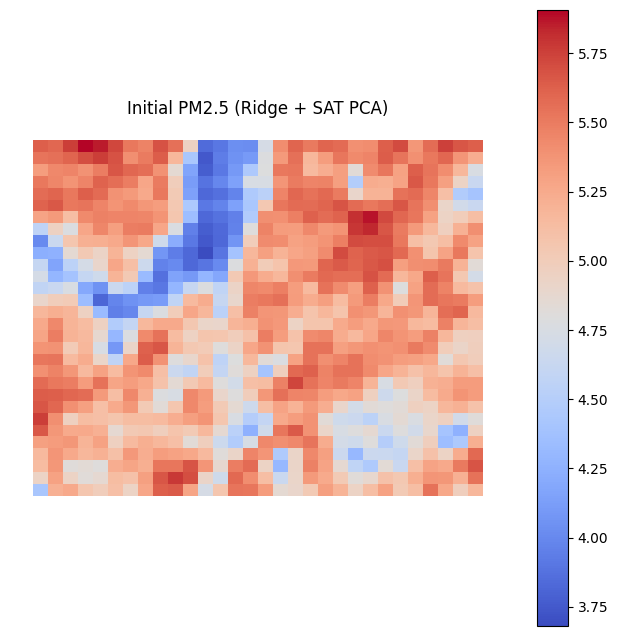

,grid_id,geometry,ndvi,ndbi,impervious,road_density,road_density_log1p,sat_pc1,sat_pc2,predicted_log_pm25_ridge,predicted_pm25_ridge
0,0,"POLYGON ((232762.527 898058.685, 232826.045 89...",0.325637,-0.207903,59.043725,0.000000,0.000000,2.659009,-1.159044,1.689149,4.414873
1,1,"POLYGON ((232762.527 898108.712, 232826.045 89...",0.217034,-0.159759,74.126761,24.844960,3.252116,0.482174,0.701937,1.780577,4.933278
2,2,"POLYGON ((232762.527 898158.739, 232826.045 89...",0.160051,-0.127417,76.528328,37.069438,3.639412,-0.255297,0.723970,1.814530,5.138193
3,3,"POLYGON ((232762.527 898208.766, 232826.045 89...",0.156749,-0.112085,77.903810,14.902990,2.766507,-0.243650,0.042402,1.817330,5.155403
4,4,"POLYGON ((232762.527 898258.793, 232826.045 89...",0.128992,-0.074170,79.078385,17.275134,2.905541,-0.764315,-0.062587,1.841892,5.308464


In [16]:
# Predict using PCA components
X_grid = grid_features[predictor_cols].to_numpy(dtype=float)
grid_features["predicted_log_pm25_ridge"] = ridge_predict(ridge_model, X_grid).clip(0, np.log1p(50))
grid_features["predicted_pm25_ridge"] = np.expm1(grid_features["predicted_log_pm25_ridge"]).clip(lower=0.0)

initial_pm25_map = gpd.GeoDataFrame(grid_features, geometry="geometry", crs=base_crs)

fig, ax = plt.subplots(figsize=(8, 8))
initial_pm25_map.plot(column="predicted_pm25_ridge", cmap="coolwarm", legend=True, ax=ax)
ax.set_axis_off()
ax.set_title("Initial PM2.5 (Ridge + SAT PCA)")
plt.show()
initial_pm25_map.head()


In [17]:
# Compute sensor residuals in log-space
sensor_model_df = sensor_cell_df[["sensor_name", "pm25"] + predictor_cols].dropna().copy()
if sensor_model_df.empty:
    raise ValueError("No sensor rows available for residual computation.")

sensor_model_df["ridge_pred_log_at_sensor"] = ridge_predict(
    ridge_model,
    sensor_model_df[predictor_cols].to_numpy(dtype=float),
)
sensor_model_df["observed_log_pm25"] = np.log1p(sensor_model_df["pm25"].clip(lower=0.0))
sensor_model_df["residual"] = sensor_model_df["observed_log_pm25"] - sensor_model_df["ridge_pred_log_at_sensor"]

sensors_proj = gdf_sensors.to_crs(initial_pm25_map.crs).copy()
sensors_proj["x"] = sensors_proj.geometry.x
sensors_proj["y"] = sensors_proj.geometry.y

sensor_residuals_df = sensor_model_df.merge(
    sensors_proj[["sensor_name", "x", "y"]],
    on="sensor_name",
    how="left",
)
sensor_residuals_df


,sensor_name,pm25,sat_pc1,sat_pc2,ridge_pred_log_at_sensor,observed_log_pm25,residual,x,y
0,Boston Carter Field,10.322884,-0.100379,-2.131453,1.821359,2.426826,0.605467,234252.312622,898834.637669
1,Boston Gainsborough Parking Garage,16.439812,-2.012823,-0.057625,1.899532,2.858756,0.959223,234191.453996,898960.969606
2,Boston Robinson Hall,0.003135,-0.030046,0.536325,1.805046,0.003130,-1.801916,234073.213353,898826.532851
3,Boston West Village B,0.884483,1.241041,-1.440358,1.756018,0.633653,-1.122365,233591.199929,898653.278770
4,Boston World Series Way,23.751881,-0.947633,0.151433,1.849311,3.208901,1.359591,233795.319059,898775.220621


Residual variogram model:
{'model': 'gaussian', 'nugget': 0.0, 'sill': 2.4987805820397417, 'range': 133.49931965358485, 'score_mse': 3.014019564015839, 'lag_centers': [128.53819628807997, 214.23032714679997, 299.92245800551996, 471.30671972295994, 642.6909814403999], 'experimental_semivariance': [0.06257171728446366, 3.263247448096711, 4.9975611640794835, 0.19846423095859103, 1.8296034435625788], 'fitted_semivariance': [1.509971350560432, 2.3085188580064817, 2.4827219036363366, 2.4987709263140325, 2.4987805818247915]}


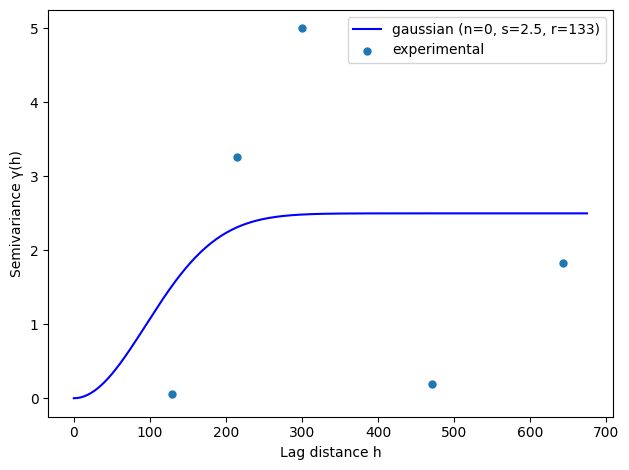

In [18]:
# Fit variogram model on residuals
res_points = list(zip(sensor_residuals_df["x"].to_list(), sensor_residuals_df["y"].to_list()))
res_values = sensor_residuals_df["residual"].to_list()

residual_variogram_model = fit_variogram_model(
    points=res_points,
    values=res_values,
)

print("Residual variogram model:")
print(residual_variogram_model)
plot_variogram_fit(residual_variogram_model)

Final PM2.5 stats: 0.005161778028700434 23.203394621045224 5.0661098357721555
Shared PM2.5 color scale: [0.005, 23.203]


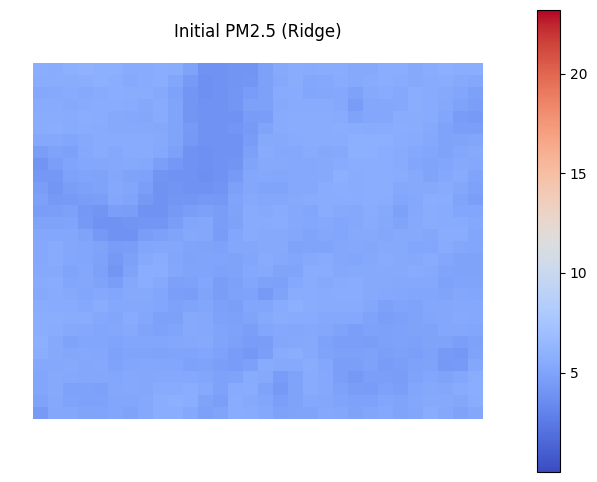

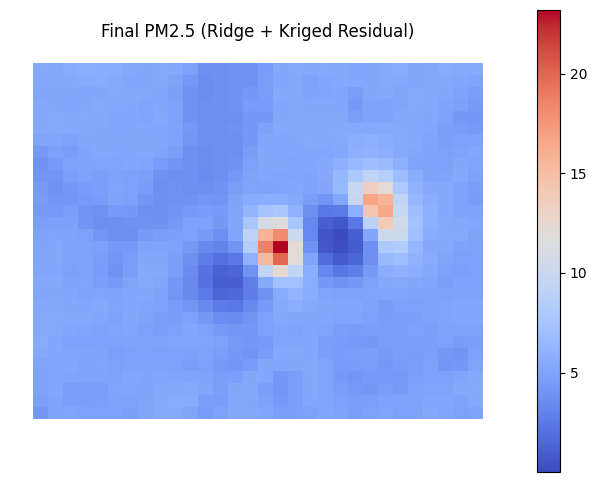

Saved initial PM2.5 figure to: /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/kriging_satellite/layers/pm25_ridge_initial_map.png
Saved final PM2.5 figure to: /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/kriging_satellite/layers/pm25_ridge_final_map.png


,grid_id,geometry,ndvi,ndbi,impervious,road_density,road_density_log1p,sat_pc1,sat_pc2,predicted_log_pm25_ridge,predicted_pm25_ridge,estimated_residual_log,final_log_pm25,final_pm25_raw,final_pm25
0,0,"POLYGON ((232762.527 898058.685, 232826.045 89...",0.325637,-0.207903,59.043725,0.000000,0.000000,2.659009,-1.159044,1.689149,4.414873,-0.03821,1.650940,4.211874,4.211874
1,1,"POLYGON ((232762.527 898108.712, 232826.045 89...",0.217034,-0.159759,74.126761,24.844960,3.252116,0.482174,0.701937,1.780577,4.933278,-0.03821,1.742367,4.710845,4.710845
2,2,"POLYGON ((232762.527 898158.739, 232826.045 89...",0.160051,-0.127417,76.528328,37.069438,3.639412,-0.255297,0.723970,1.814530,5.138193,-0.03821,1.776320,4.908077,4.908077
3,3,"POLYGON ((232762.527 898208.766, 232826.045 89...",0.156749,-0.112085,77.903810,14.902990,2.766507,-0.243650,0.042402,1.817330,5.155403,-0.03821,1.779120,4.924642,4.924642
4,4,"POLYGON ((232762.527 898258.793, 232826.045 89...",0.128992,-0.074170,79.078385,17.275134,2.905541,-0.764315,-0.062587,1.841892,5.308464,-0.03821,1.803682,5.071965,5.071965


In [19]:
# Krige log-space residuals and produce final PM2.5 map
query_points = [(geom.centroid.x, geom.centroid.y) for geom in initial_pm25_map.geometry]
res_points = list(zip(sensor_residuals_df["x"].to_list(), sensor_residuals_df["y"].to_list()))
res_values = sensor_residuals_df["residual"].to_list()

estimated_residuals = ordinary_kriging_predict(
    points=res_points,
    values=res_values,
    fit=residual_variogram_model,
    query_points=query_points,
)

final_pm25_map = initial_pm25_map.copy()
final_pm25_map["estimated_residual_log"] = estimated_residuals
final_pm25_map["final_log_pm25"] = (
    final_pm25_map["predicted_log_pm25_ridge"] + final_pm25_map["estimated_residual_log"]
).clip(0, np.log1p(50))
final_pm25_map["final_pm25_raw"] = np.expm1(final_pm25_map["final_log_pm25"])
final_pm25_map["final_pm25"] = final_pm25_map["final_pm25_raw"].clip(lower=0.0)

print(
    "Final PM2.5 stats:",
    float(final_pm25_map["final_pm25"].min()),
    float(final_pm25_map["final_pm25"].max()),
    float(final_pm25_map["final_pm25"].mean()),
)

PM25_INITIAL_FIG_PATH = LAYER_DIR / "pm25_ridge_initial_map.png"
PM25_FINAL_FIG_PATH = LAYER_DIR / "pm25_ridge_final_map.png"
PM25_INITIAL_FIG_PATH.parent.mkdir(parents=True, exist_ok=True)
PM25_CMAP = "coolwarm"
pm25_min = float(min(initial_pm25_map["predicted_pm25_ridge"].min(), final_pm25_map["final_pm25"].min()))
pm25_max = float(max(initial_pm25_map["predicted_pm25_ridge"].max(), final_pm25_map["final_pm25"].max()))
print(f"Shared PM2.5 color scale: [{pm25_min:.3f}, {pm25_max:.3f}]")

fig_initial, ax_initial = plt.subplots(figsize=(8, 6))
initial_pm25_map.plot(
    column="predicted_pm25_ridge",
    cmap=PM25_CMAP,
    legend=True,
    vmin=pm25_min,
    vmax=pm25_max,
    ax=ax_initial,
)
ax_initial.set_axis_off()
ax_initial.set_title("Initial PM2.5 (Ridge)")
fig_initial.savefig(PM25_INITIAL_FIG_PATH, dpi=300, bbox_inches="tight")
plt.show()

fig_final, ax_final = plt.subplots(figsize=(8, 6))
final_pm25_map.plot(
    column="final_pm25",
    cmap=PM25_CMAP,
    legend=True,
    vmin=pm25_min,
    vmax=pm25_max,
    ax=ax_final,
)
ax_final.set_axis_off()
ax_final.set_title("Final PM2.5 (Ridge + Kriged Residual)")
fig_final.savefig(PM25_FINAL_FIG_PATH, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved initial PM2.5 figure to: {PM25_INITIAL_FIG_PATH}")
print(f"Saved final PM2.5 figure to: {PM25_FINAL_FIG_PATH}")

final_pm25_map.head()

In [20]:
# Save final output
PM25_OUTPUT_PATH = LAYER_DIR / "pm25_ridge_kriging_grid.geojson"
PM25_OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
final_pm25_map.to_file(PM25_OUTPUT_PATH, driver="GeoJSON")
print(f"Saved final PM2.5 map to: {PM25_OUTPUT_PATH}")

Saved final PM2.5 map to: /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/kriging_satellite/layers/pm25_ridge_kriging_grid.geojson
